# Traffic Sign Detection Using Deep Learning

## Project Introduction

Traffic sign recognition is an important application of computer vision and deep learning. This project aims to develop a Convolutional Neural Network (CNN) that can classify traffic sign images into 43 different categories.

The project uses the German Traffic Sign Recognition Benchmark (GTSRB) dataset, which contains images of different traffic signs.

The images are preprocessed by resizing them to 32 × 32 pixels and normalizing their pixel values. A CNN model is trained to learn visual features and classify traffic signs.

The trained model can predict the traffic sign category from an uploaded image and display the predicted traffic sign name.

## Project Objectives

* Perform image preprocessing and normalization.
* Develop a CNN model for traffic sign classification.
* Train and evaluate the model using traffic sign images.
* Visualize model performance using accuracy and loss graphs.
* Generate a confusion matrix and classification report.
* Predict traffic signs from user-uploaded images.


## 1. Dataset Loading and Extraction

The German Traffic Sign Recognition Benchmark (GTSRB) dataset is used for this project. It contains traffic sign images belonging to 43 different classes.

The dataset is stored in Google Drive as a ZIP file. Google Drive is mounted in Google Colab, and the ZIP file is extracted into the Colab environment.

The extracted dataset contains the following folders and files:

* **Train:** Contains training images organized into class-specific folders.
* **Test:** Contains images used for final model evaluation.
* **Meta:** Contains reference images for traffic sign classes.
* **Train.csv:** Contains training image information and labels.
* **Test.csv:** Contains test image information and labels.
* **Meta.csv:** Contains metadata for the traffic sign classes.

The dataset is loaded and inspected before preprocessing and model development.


In [1]:

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import os

dataset_path = "/content/drive/MyDrive/Datasets/Traffic_Sign"

print(os.listdir(dataset_path))

['PRAICP-1002-TrafSignDetc.zip']


In [3]:

import os
import zipfile

# Path to the uploaded ZIP file
zip_path = "/content/drive/MyDrive/Datasets/Traffic_Sign/PRAICP-1002-TrafSignDetc.zip"

# Extract dataset into Colab
extract_path = "/content/traffic_sign_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files:", os.listdir(extract_path))

Dataset extracted successfully!
Files: ['test', 'Meta', 'Test', 'meta', 'Test.csv', 'Meta.csv', 'Train', 'train', 'Train.csv']


## 2. Dataset Exploration and Visualization

Exploratory data analysis is performed to understand the structure and characteristics of the traffic sign dataset.

The training dataset contains 39,209 images belonging to 43 different traffic sign classes.

Each class is represented by a numerical label ranging from 0 to 42.

Sample images from different classes are displayed using Matplotlib to examine their visual characteristics.

The images contain different types of traffic signs, including speed limits, warning signs, prohibition signs, and mandatory direction signs.

The dataset includes variations in image size, lighting conditions, viewing angles, and image quality.

Understanding these characteristics helps in selecting appropriate preprocessing techniques and developing the CNN model.


In [4]:

import os

train_path = "/content/traffic_sign_dataset/Train"

# Get the traffic sign class folders
classes = sorted(os.listdir(train_path))

print("Total traffic sign classes:", len(classes))
print("Class names:", classes)

# Count the training images
total_images = 0

for class_name in classes:
    class_path = os.path.join(train_path, class_name)

    if os.path.isdir(class_path):
        image_count = len(os.listdir(class_path))
        total_images += image_count

print("Total training images:", total_images)

Total traffic sign classes: 43
Class names: ['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '5', '6', '7', '8', '9']
Total training images: 39209


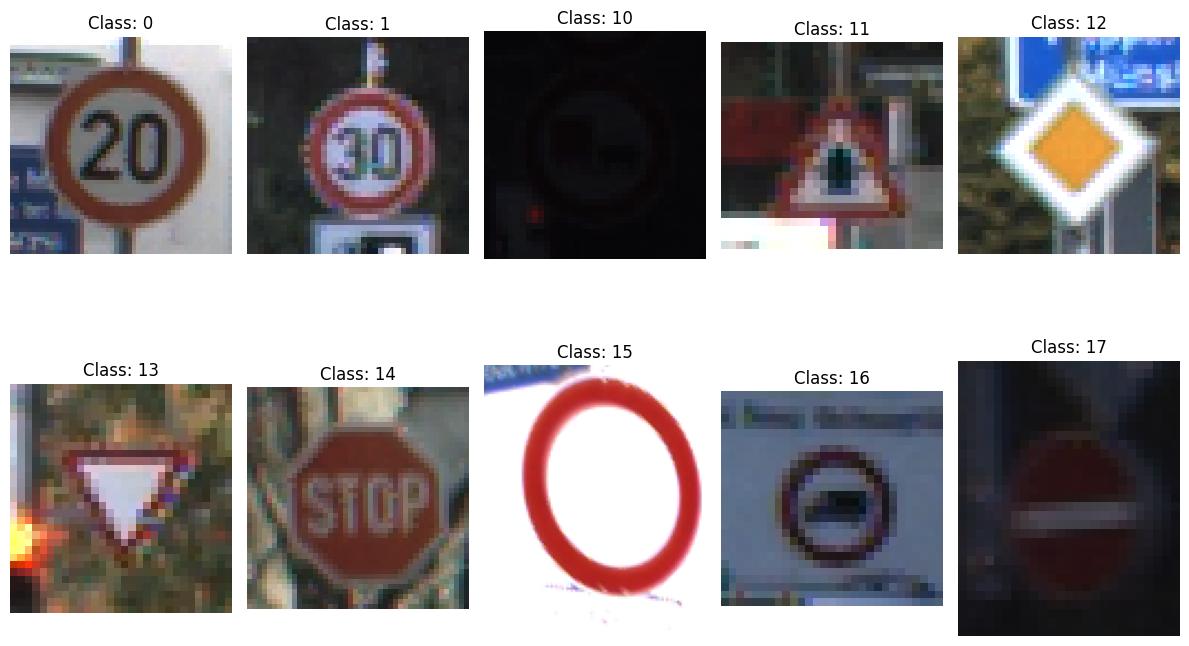

In [5]:

import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(12, 8))

# Display images from the first 10 classes
for i, class_name in enumerate(classes[:10]):

    class_path = os.path.join(train_path, class_name)

    if not os.path.isdir(class_path):
        continue

    images = os.listdir(class_path)

    if len(images) == 0:
        continue

    image_path = os.path.join(class_path, images[0])

    img = Image.open(image_path)

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title("Class: " + class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Image Preprocessing

Image preprocessing is performed to prepare the traffic sign images for CNN model training.

The following preprocessing operations are applied:

**1. Image resizing**

All images are resized to 32 × 32 pixels to maintain a uniform input size.

**2. RGB conversion**

The images are converted into RGB format to ensure that each image contains three color channels.

**3. NumPy array conversion**

The images are converted into NumPy arrays for numerical processing.

**4. Image normalization**

Pixel values are normalized from the original range of 0–255 to the range of 0–1 by dividing them by 255.

**5. Label preparation**

Each image is assigned its corresponding traffic sign class ID.

After preprocessing, the training dataset contains 39,209 images with dimensions of 32 × 32 × 3.


In [6]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

In [7]:

# Dataset path
train_path = "/content/traffic_sign_dataset/Train"

# Image size
IMG_SIZE = (32, 32)

# Lists to store images and labels
images = []
labels = []

# Load images from all 43 classes
for class_id in tqdm(range(43)):

    class_path = os.path.join(
        train_path, str(class_id)
    )

    for image_name in os.listdir(class_path):

        image_path = os.path.join(
            class_path, image_name
        )

        # Open and preprocess the image
        with Image.open(image_path) as img:
            img = img.convert("RGB")
            img = img.resize(IMG_SIZE)

            # Convert image to NumPy array
            img_array = np.array(
                img, dtype=np.uint8
            )

        images.append(img_array)
        labels.append(class_id)

# Convert lists into NumPy arrays
X = np.array(images, dtype=np.uint8)
y = np.array(labels, dtype=np.int64)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Total classes:", len(np.unique(y)))

  0%|          | 0/43 [00:00<?, ?it/s]

Images shape: (39209, 32, 32, 3)
Labels shape: (39209,)
Total classes: 43


In [8]:

# Normalize pixel values
X = X.astype("float32") / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

print("Final images shape:", X.shape)
print("Final labels shape:", y.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Final images shape: (39209, 32, 32, 3)
Final labels shape: (39209,)


## 4. Training and Validation Data Splitting

The preprocessed dataset is divided into training and validation sets using the `train_test_split()` function from Scikit-learn.

The dataset is split using an 80:20 ratio.

* Training dataset: 31,367 images (80%)
* Validation dataset: 7,842 images (20%)

The training dataset is used to train the CNN model, while the validation dataset is used to monitor its performance during training.

The `stratify` parameter is used to maintain approximately the same class proportions in both datasets.

A fixed random state of 42 is used to make the data split reproducible.

The separate test dataset is reserved for final model evaluation.


In [9]:
from sklearn.model_selection import train_test_split

# Split dataset into 80% training and 20% validation

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training images: (31367, 32, 32, 3)
Validation images: (7842, 32, 32, 3)
Training labels: (31367,)
Validation labels: (7842,)


## 5. CNN Model Development

A Convolutional Neural Network (CNN) is developed using TensorFlow and Keras to classify traffic sign images into 43 categories.

The model uses the Sequential architecture and consists of the following layers:

**Convolutional layers (Conv2D):** Extract visual features such as edges, shapes, colors, and patterns from traffic sign images.

**Max pooling layers (MaxPooling2D):** Reduce the spatial dimensions of feature maps while retaining important information.

**Dropout layers:** Randomly deactivate selected neurons during training to help reduce overfitting.

**Flatten layer:** Converts the extracted feature maps into a one-dimensional feature vector.

**Dense layer:** Learns patterns from the extracted features to perform classification.

**Output layer:** Contains 43 neurons with Softmax activation, producing a predicted probability for each traffic sign class.

The model accepts images with dimensions of 32 × 32 × 3.

The CNN contains 1,125,451 trainable parameters.


In [10]:

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [11]:

# Build the CNN model

model = Sequential([

    # Input layer
    Input(shape=(32, 32, 3)),

    # First convolutional block
    Conv2D(
        32,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    Conv2D(
        32,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    MaxPooling2D(pool_size=(2, 2)),

    Dropout(0.25),

    # Second convolutional block
    Conv2D(
        64,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    Conv2D(
        64,
        (3, 3),
        activation='relu',
        padding='same'
    ),

    MaxPooling2D(pool_size=(2, 2)),

    Dropout(0.25),

    # Flatten layer
    Flatten(),

    # Fully connected layer
    Dense(256, activation='relu'),

    Dropout(0.5),

    # Output layer - 43 traffic sign classes
    Dense(43, activation='softmax')

])

print("CNN model created successfully!")

CNN model created successfully!


## 6. Model Compilation and Training

The CNN model is compiled using the following configuration:

* **Optimizer:** Adam
* **Loss function:** Sparse Categorical Crossentropy
* **Evaluation metric:** Accuracy
* **Batch size:** 64
* **Maximum epochs:** 20

The Adam optimizer is used to update the model parameters during training.

Sparse Categorical Crossentropy is selected because the traffic sign labels are represented as integer class IDs.

The model is trained using 31,367 images and validated using 7,842 images.

EarlyStopping is used to stop training when validation loss does not improve for five consecutive epochs.

ModelCheckpoint saves the model with the lowest validation loss to Google Drive.

The training process produces accuracy and loss values for both training and validation datasets.


In [12]:

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

model.summary()

Model compiled successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,125,451 (4.29 MB)

 Trainable params: 1,125,451 (4.29 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Save the model with the lowest validation loss
checkpoint = ModelCheckpoint(
    '/content/drive/MyDrive/Traffic_Sign_Detection/best_traffic_sign_model.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min'
)

print("Training callbacks configured!")

Training callbacks configured!


In [14]:

# Train the CNN model

history = model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=20,
    validation_data=(X_val, y_val),
    callbacks=[
        early_stopping,
        checkpoint
    ],
    verbose=1
)

print("Model training completed!")

# Display the final training results

print("Final Training Accuracy:",
      history.history['accuracy'][-1])

print("Final Validation Accuracy:",
      history.history['val_accuracy'][-1])

print("Final Training Loss:",
      history.history['loss'][-1])

print("Final Validation Loss:",
      history.history['val_loss'][-1])

print("Best Validation Accuracy:",
      max(history.history['val_accuracy']))

Epoch 1/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 193s 389ms/step - accuracy: 0.5314 - loss: 1.6305 - val_accuracy: 0.9200 - val_loss: 0.2961
Epoch 2/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 184s 374ms/step - accuracy: 0.8867 - loss: 0.3592 - val_accuracy: 0.9855 - val_loss: 0.0608
Epoch 3/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 210s 391ms/step - accuracy: 0.9442 - loss: 0.1807 - val_accuracy: 0.9912 - val_loss: 0.0410
Epoch 4/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 204s 396ms/step - accuracy: 0.9614 - loss: 0.1249 - val_accuracy: 0.9939 - val_loss: 0.0254
Epoch 5/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 206s 406ms/step - accuracy: 0.9712 - loss: 0.0929 - val_accuracy: 0.9950 - val_loss: 0.0215
Epoch 6/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 183s 367ms/step - accuracy: 0.9775 - loss: 0.0726 - val_accuracy: 0.9949 - val_loss: 0.0214
Epoch 7/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 203s 369ms/step - accuracy: 0.9791 - loss: 0.0669 - val_accuracy: 0.9960 - val_loss: 0.0144
Epoch 8/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 182s 371ms/step - accuracy: 0.9817 -

## 7. Training Performance Visualization

Training and validation accuracy and loss are visualized using Matplotlib.

### Accuracy Graph

The accuracy graph displays the changes in training and validation accuracy across the training epochs.

The final training accuracy is 99.17%, and the final validation accuracy is 99.80%.

### Loss Graph

The loss graph displays the changes in training and validation loss during model training.

The final training loss is 0.0262, while the final validation loss is 0.0077.

The graphs show that the CNN model learned effectively during training.

The training and validation results are compared to examine model convergence and identify potential overfitting.

Both graphs are saved for project documentation and evaluation.


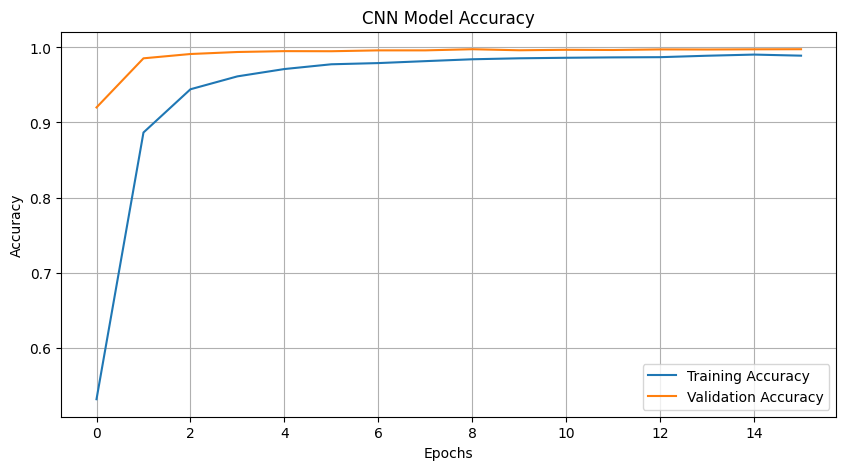

In [15]:

import matplotlib.pyplot as plt

# Plot accuracy graph
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

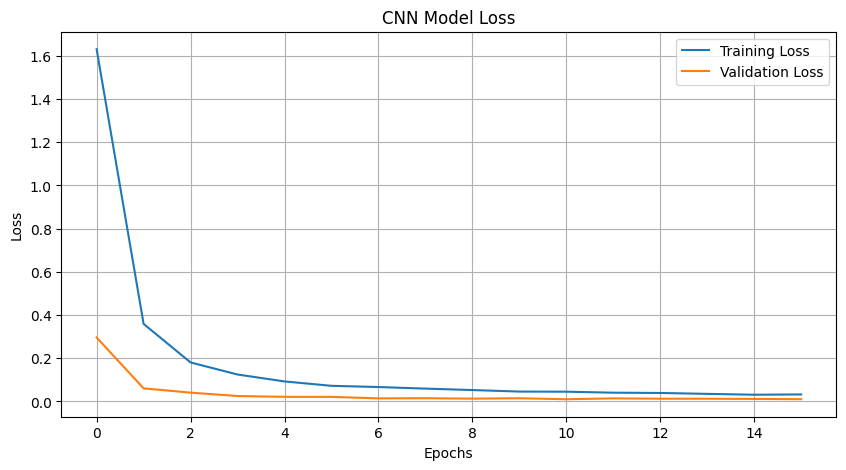

In [16]:

# Plot loss graph
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [17]:

import os
import matplotlib.pyplot as plt

save_path = "/content/drive/MyDrive/Traffic_Sign_Detection"

os.makedirs(save_path, exist_ok=True)

# Save accuracy graph
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(save_path, 'accuracy_graph.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# Save loss graph
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(save_path, 'loss_graph.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.close()

print("Accuracy and loss graphs saved successfully!")

Accuracy and loss graphs saved successfully!


## 8. Model Evaluation Using the Test Dataset

The trained CNN model is evaluated using a separate test dataset containing 12,630 traffic sign images.

The test images are resized to 32 × 32 pixels, converted into RGB format, and normalized using the same preprocessing steps applied to the training images.

The saved CNN model with the lowest validation loss is loaded from Google Drive.

The model is evaluated using the test images and their corresponding actual class labels.

### Test Results

| Evaluation Metric     | Result |
| --------------------- | -----: |
| Total test images     | 12,630 |
| Test accuracy         | 97.24% |
| Test loss             | 0.1245 |
| Correct predictions   | 12,282 |
| Incorrect predictions |    348 |

The model correctly classified 12,282 out of 12,630 test images.

The test accuracy is lower than the validation accuracy, indicating that performance differs between the validation and separate test datasets.


In [18]:

import os
import pandas as pd

# Dataset location
dataset_path = "/content/traffic_sign_dataset"

# Load test CSV file
test_df = pd.read_csv(
    os.path.join(dataset_path, "Test.csv")
)

print("Test dataset shape:", test_df.shape)

print("\nColumn names:")
print(test_df.columns.tolist())

print("\nFirst 5 rows:")
print(test_df.head())

Test dataset shape: (12630, 8)

Column names:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

First 5 rows:
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId            Path
0     53      54       6       5      48      49       16  Test/00000.png
1     42      45       5       5      36      40        1  Test/00001.png
2     48      52       6       6      43      47       38  Test/00002.png
3     27      29       5       5      22      24       33  Test/00003.png
4     60      57       5       5      55      52       11  Test/00004.png


In [19]:

import numpy as np
from PIL import Image
from tqdm.auto import tqdm

# Lists to store test images and labels
test_images = []
test_labels = []

for _, row in tqdm(
    test_df.iterrows(),
    total=len(test_df)
):

    # Get image path from CSV
    image_path = os.path.join(
        dataset_path,
        row["Path"]
    )

    # Open and preprocess image
    with Image.open(image_path) as img:

        img = img.convert("RGB")

        img = img.resize((32, 32))

        img_array = np.array(
            img,
            dtype=np.float32
        ) / 255.0

    test_images.append(img_array)

    test_labels.append(
        int(row["ClassId"])
    )

# Convert into NumPy arrays
X_test = np.array(
    test_images,
    dtype=np.float32
)

y_test = np.array(
    test_labels,
    dtype=np.int64
)

print("Test images shape:", X_test.shape)

print("Test labels shape:", y_test.shape)

  0%|          | 0/12630 [00:00<?, ?it/s]

Test images shape: (12630, 32, 32, 3)
Test labels shape: (12630,)


In [20]:

import tensorflow as tf

# Load the best saved CNN model
model_path = (
    "/content/drive/MyDrive/"
    "Traffic_Sign_Detection/"
    "best_traffic_sign_model.keras"
)

best_model = tf.keras.models.load_model(
    model_path
)

# Evaluate the model
test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest Accuracy: {:.2f}%".format(
    test_accuracy * 100
))

print("Test Loss: {:.4f}".format(
    test_loss
))

395/395 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.9724 - loss: 0.1245

Test Accuracy: 97.24%
Test Loss: 0.1245


In [21]:

import numpy as np

# Predict traffic signs from the test dataset
predictions = best_model.predict(
    X_test,
    batch_size=128,
    verbose=1
)

# Convert prediction probabilities into class IDs
y_pred = np.argmax(predictions, axis=1)

print("Total predictions:", len(y_pred))

print("First 10 actual labels:", y_test[:10])

print("First 10 predicted labels:", y_pred[:10])

99/99 ━━━━━━━━━━━━━━━━━━━━ 22s 216ms/step
Total predictions: 12630
First 10 actual labels: [16  1 38 33 11 38 18 12 25 35]
First 10 predicted labels: [16  1 38 33 11 38 18 12 25 35]


## 9. Traffic Sign Prediction Visualization

The trained CNN model is used to predict the classes of images from the test dataset.

The model generates prediction probabilities for all 43 traffic sign classes.

The class with the highest predicted probability is selected using the NumPy `argmax()` function.

Randomly selected test images are displayed along with their actual and predicted class IDs.

Correct predictions are displayed with green titles, while incorrect predictions are displayed with red titles.

Incorrectly classified images are also visualized separately to analyze the model's prediction errors.

Some incorrectly classified images have poor lighting, low resolution, or visually similar traffic sign patterns.

These examples help identify areas where the model's recognition performance could be improved.


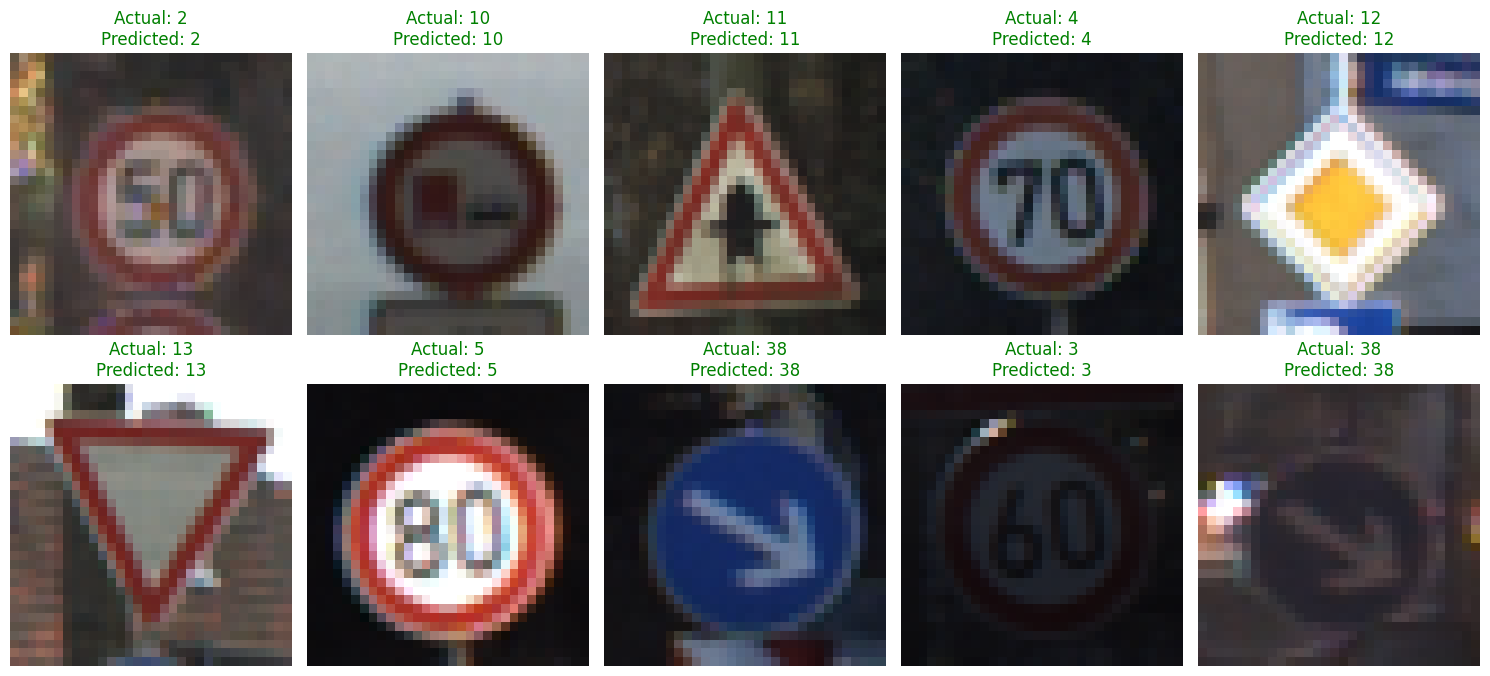

In [22]:

import matplotlib.pyplot as plt

# Select 10 random test images
np.random.seed(42)

sample_indices = np.random.choice(
    len(X_test),
    size=10,
    replace=False
)

plt.figure(figsize=(15, 7))

for i, index in enumerate(sample_indices):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[index])

    actual = y_test[index]
    predicted = y_pred[index]

    # Display actual and predicted class IDs
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color="green" if actual == predicted else "red"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Total incorrect predictions: 348


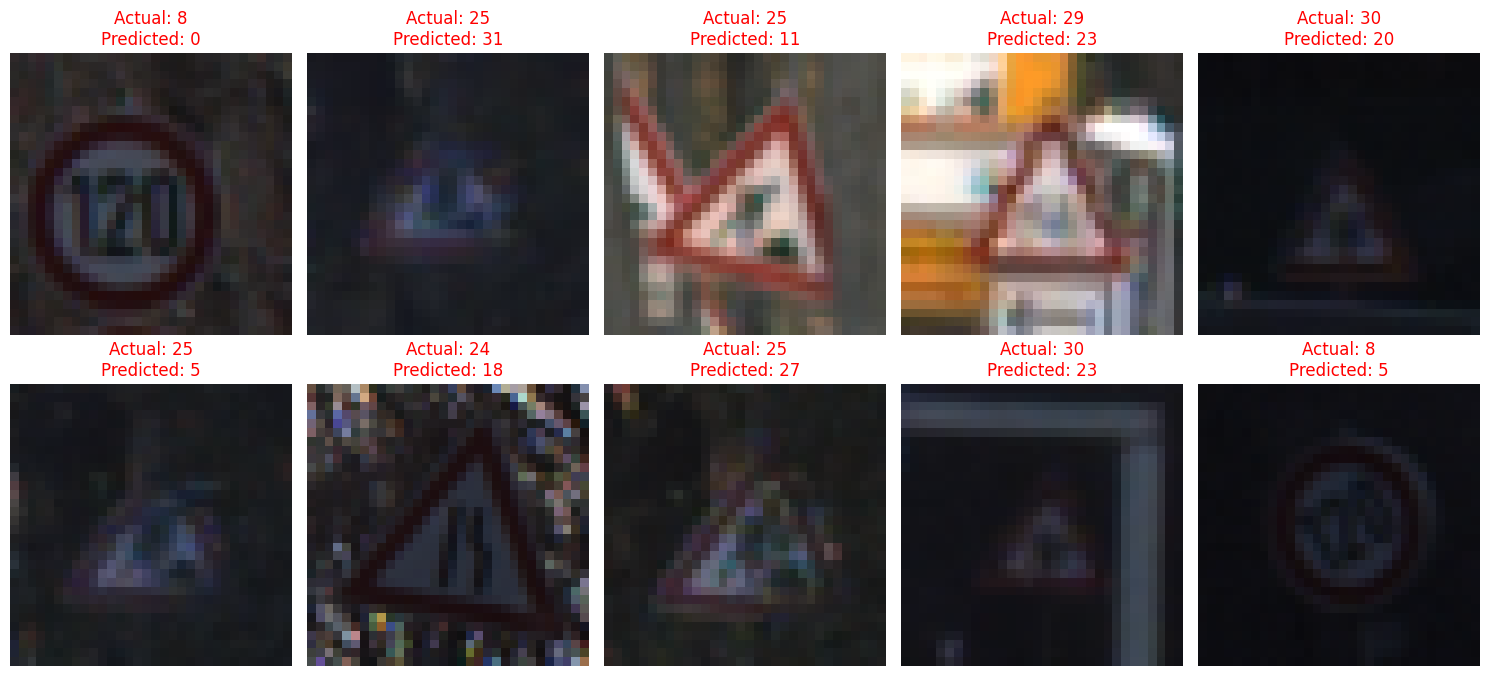

In [23]:

# Find incorrectly predicted images
wrong_indices = np.where(
    y_pred != y_test
)[0]

print("Total incorrect predictions:",
      len(wrong_indices))

# Display up to 10 incorrect predictions
plt.figure(figsize=(15, 7))

for i, index in enumerate(wrong_indices[:10]):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[index])

    plt.title(
        f"Actual: {y_test[index]}\n"
        f"Predicted: {y_pred[index]}",
        color="red"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## 10. Confusion Matrix and Classification Report

A confusion matrix and classification report are generated to evaluate the CNN model's performance across all 43 traffic sign classes.

### Confusion Matrix

The confusion matrix compares the actual class labels with the predicted class labels.

The diagonal values represent correctly classified images, while values outside the diagonal represent incorrect predictions.

The confusion matrix is visualized using Seaborn and Matplotlib.

### Classification Report

The classification report provides the following evaluation metrics for each class:

* **Precision:** The proportion of predictions for a class that are correct.
* **Recall:** The proportion of actual images of a class that are correctly identified.
* **F1-score:** The harmonic mean of precision and recall.
* **Support:** The number of test images belonging to each class.

### Overall Classification Results

| Metric                    | Result |
| ------------------------- | -----: |
| Accuracy                  | 97.24% |
| Macro-average precision   | 95.73% |
| Macro-average recall      | 95.07% |
| Macro-average F1-score    | 95.17% |
| Weighted-average F1-score | 97.22% |

The results show that the CNN performs well across most traffic sign classes, although performance varies between individual classes.

The confusion matrix and classification report are saved for project documentation.


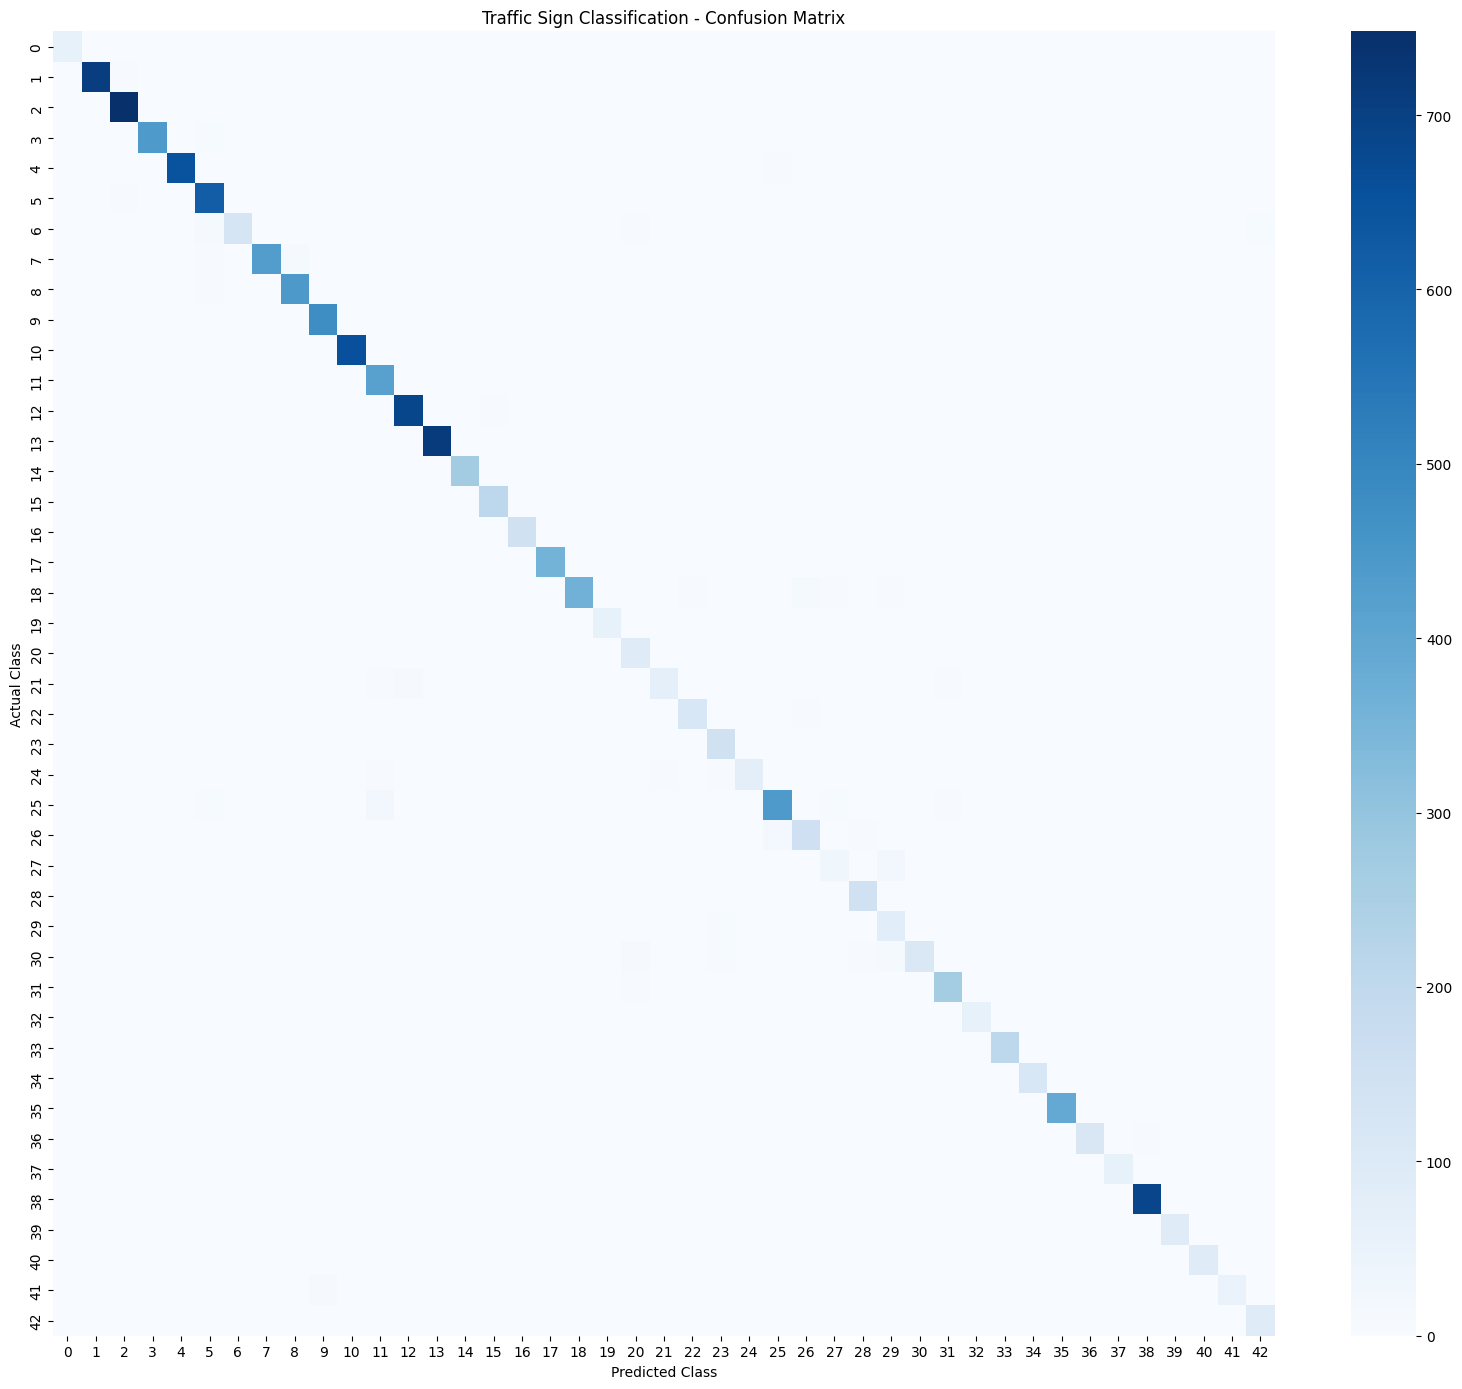

In [24]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(43)
)

# Display confusion matrix
plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=range(43),
    yticklabels=range(43)
)

plt.title("Traffic Sign Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [25]:

from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    labels=range(43),
    digits=4,
    zero_division=0
)

print("Traffic Sign Classification Report")
print(report)

Traffic Sign Classification Report
              precision    recall  f1-score   support

           0     0.9836    1.0000    0.9917        60
           1     0.9861    0.9847    0.9854       720
           2     0.9855    0.9973    0.9914       750
           3     0.9844    0.9800    0.9822       450
           4     0.9939    0.9864    0.9901       660
           5     0.9463    0.9794    0.9626       630
           6     1.0000    0.8400    0.9130       150
           7     0.9885    0.9556    0.9718       450
           8     0.9610    0.9844    0.9726       450
           9     0.9815    0.9958    0.9886       480
          10     0.9954    0.9924    0.9939       660
          11     0.9350    0.9929    0.9630       420
          12     0.9814    0.9928    0.9870       690
          13     0.9958    0.9931    0.9944       720
          14     1.0000    1.0000    1.0000       270
          15     0.9812    0.9952    0.9882       210
          16     1.0000    1.0000    1.0000   

In [26]:

import os

save_path = "/content/drive/MyDrive/Traffic_Sign_Detection"

os.makedirs(save_path, exist_ok=True)

# Save confusion matrix
plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=range(43),
    yticklabels=range(43)
)

plt.title("Traffic Sign Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    os.path.join(save_path, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Save classification report
report_path = os.path.join(
    save_path,
    "classification_report.txt"
)

with open(report_path, "w") as file:
    file.write(report)

print("Confusion matrix and classification report saved!")

Confusion matrix and classification report saved!


## 11. Traffic Sign Prediction Function

A prediction function is developed to classify individual traffic sign images using the trained CNN model.

The function performs the following operations:

1. Loads the input image and converts it into RGB format.
2. Resizes the image to 32 × 32 pixels.
3. Normalizes the image pixel values to the range of 0–1.
4. Adds a batch dimension to match the model's input requirements.
5. Uses the trained CNN model to generate prediction probabilities.
6. Identifies the predicted traffic sign class using `argmax()`.
7. Converts the predicted class ID into its corresponding traffic sign name.
8. Displays the original image, predicted traffic sign name, and model confidence.

The prediction function is tested using an image from the test dataset.

The model correctly identifies the test image as "Vehicles over 3.5 tons prohibited."

The function enables traffic sign classification without manually processing each image.


In [27]:

# Traffic sign class names

class_names = [
    "Speed limit (20km/h)",
    "Speed limit (30km/h)",
    "Speed limit (50km/h)",
    "Speed limit (60km/h)",
    "Speed limit (70km/h)",
    "Speed limit (80km/h)",
    "End of speed limit (80km/h)",
    "Speed limit (100km/h)",
    "Speed limit (120km/h)",
    "No passing",
    "No passing for vehicles over 3.5 tons",
    "Right-of-way at the next intersection",
    "Priority road",
    "Yield",
    "Stop",
    "No vehicles",
    "Vehicles over 3.5 tons prohibited",
    "No entry",
    "General caution",
    "Dangerous curve to the left",
    "Dangerous curve to the right",
    "Double curve",
    "Bumpy road",
    "Slippery road",
    "Road narrows on the right",
    "Road work",
    "Traffic signals",
    "Pedestrians",
    "Children crossing",
    "Bicycles crossing",
    "Beware of ice/snow",
    "Wild animals crossing",
    "End of all speed and passing limits",
    "Turn right ahead",
    "Turn left ahead",
    "Ahead only",
    "Go straight or right",
    "Go straight or left",
    "Keep right",
    "Keep left",
    "Roundabout mandatory",
    "End of no passing",
    "End of no passing for vehicles over 3.5 tons"
]

print("Total traffic sign names:", len(class_names))

Total traffic sign names: 43


In [28]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def predict_traffic_sign(image_path):

    # Load the original image
    img = Image.open(image_path).convert("RGB")

    # Resize image to match CNN input
    resized_img = img.resize((32, 32))

    # Convert image into a NumPy array
    img_array = np.array(
        resized_img,
        dtype=np.float32
    ) / 255.0

    # Add batch dimension
    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    # Predict traffic sign
    prediction = best_model.predict(
        img_array,
        verbose=0
    )

    # Get predicted class ID
    predicted_class = int(
        np.argmax(prediction[0])
    )

    # Get predicted class name
    predicted_name = class_names[predicted_class]

    # Get prediction confidence
    confidence = float(
        np.max(prediction[0]) * 100
    )

    # Display original image
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Predicted: {predicted_name}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted Class ID:", predicted_class)
    print("Traffic Sign:", predicted_name)
    print(f"Confidence: {confidence:.2f}%")

Actual Class ID: 16
Actual Traffic Sign: Vehicles over 3.5 tons prohibited


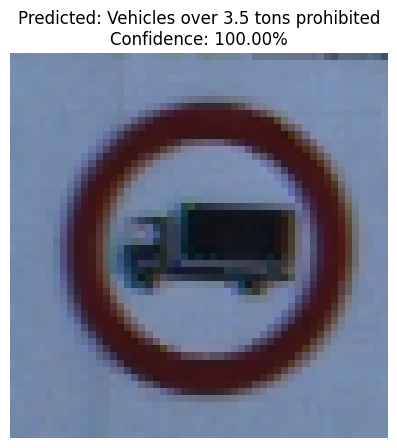

Predicted Class ID: 16
Traffic Sign: Vehicles over 3.5 tons prohibited
Confidence: 100.00%


In [29]:

import os

# Select the first image from the test dataset
sample_path = os.path.join(
    dataset_path,
    test_df.iloc[0]["Path"]
)

# Display the actual traffic sign
actual_class = int(
    test_df.iloc[0]["ClassId"]
)

print("Actual Class ID:", actual_class)
print("Actual Traffic Sign:", class_names[actual_class])

# Predict the traffic sign
predict_traffic_sign(sample_path)

## 12. Traffic Sign Prediction Using an Uploaded Image

An image-upload feature is implemented using the Google Colab `files.upload()` function.

This feature allows users to select and upload a traffic sign image from their computer.

After uploading the image, the prediction function preprocesses it and uses the trained CNN model to identify the traffic sign class.

The predicted traffic sign name and confidence percentage are displayed along with the uploaded image.

The feature is tested using a traffic sign image, which the model identifies as "Right-of-way at the next intersection."

The model reports a confidence of 100.00% for this prediction.

The displayed confidence is the model's rounded predicted probability and does not guarantee that every prediction is correct.

This feature demonstrates how the trained CNN model can be used to classify user-provided traffic sign images.


Saving 00004.png to 00004.png

Uploaded image: 00004.png


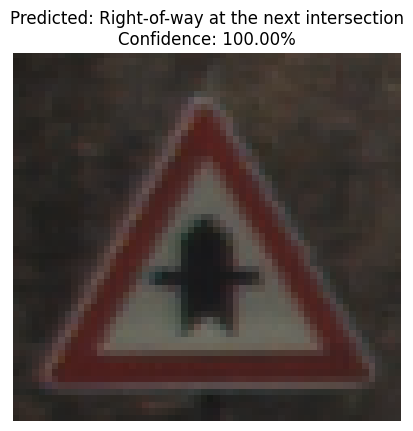

Predicted Class ID: 11
Traffic Sign: Right-of-way at the next intersection
Confidence: 100.00%


In [31]:

from google.colab import files

# Upload a traffic sign image
uploaded = files.upload()

# Predict each uploaded image
for filename in uploaded.keys():

    print("\nUploaded image:", filename)

    predict_traffic_sign(filename)

## 13. Final Project Verification

The final verification step confirms that the trained CNN model has been saved successfully and that the dataset dimensions match the model's input and output requirements.

The project uses 31,367 training images, 7,842 validation images, and 12,630 test images across 43 traffic sign classes.

The trained model accepts images with dimensions of 32 × 32 × 3 and produces predictions for 43 traffic sign categories.

This verification confirms that the notebook contains the necessary components for traffic sign classification and evaluation.


In [32]:

import os

model_path = "/content/drive/MyDrive/Traffic_Sign_Detection/best_traffic_sign_model.keras"

if os.path.exists(model_path):
    print("Trained model is saved successfully!")
else:
    print("Model file not found!")

Trained model is saved successfully!


In [33]:

print("Training images:", X_train.shape[0])
print("Validation images:", X_val.shape[0])
print("Test images:", X_test.shape[0])

print("Number of classes:", len(class_names))

print("Model input shape:", best_model.input_shape)
print("Model output shape:", best_model.output_shape)

Training images: 31367
Validation images: 7842
Test images: 12630
Number of classes: 43
Model input shape: (None, 32, 32, 3)
Model output shape: (None, 43)


## Project Conclusion

In this project, a Convolutional Neural Network (CNN) was developed to classify traffic signs into 43 different categories.

The model was trained using 31,367 images and validated using 7,842 images. It was evaluated on a separate test dataset containing 12,630 images.

The CNN model achieved a test accuracy of **97.24%**, demonstrating its ability to classify traffic sign images with high accuracy on the test dataset.

The model's performance was evaluated using accuracy and loss graphs, a confusion matrix, and a classification report.

An image-upload feature was also implemented in Google Colab, allowing users to upload traffic sign images and obtain predictions.

The project demonstrates the application of deep learning and computer vision techniques to traffic sign classification.

### Future Enhancements

* Improve recognition of traffic signs under poor lighting conditions.
* Apply data augmentation to improve model generalization.
* Extend the project to detect and classify traffic signs in full road images.
* Develop a real-time traffic sign recognition system using a camera.
